In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [2]:

df = pd.read_csv("CC GENERAL.csv")
print("Shape:", df.shape)


Shape: (8950, 18)


In [3]:
display(df.head())


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [4]:
display(df.tail())


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.50,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.00,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.25,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.25,6
8949,C19190,372.708075,0.666667,1093.25,1093.25,0.00,127.040008,0.666667,0.666667,0.000000,0.333333,2,23,1200.0,63.165404,88.288956,0.00,6


In [5]:
print(df.isna().sum())

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64


In [6]:
df.isnull().mean()*100

,0
CUST_ID,0.000000
BALANCE,0.000000
BALANCE_FREQUENCY,0.000000
PURCHASES,0.000000
ONEOFF_PURCHASES,0.000000
INSTALLMENTS_PURCHASES,0.000000
CASH_ADVANCE,0.000000
PURCHASES_FREQUENCY,0.000000
ONEOFF_PURCHASES_FREQUENCY,0.000000
PURCHASES_INSTALLMENTS_FREQUENCY,0.000000


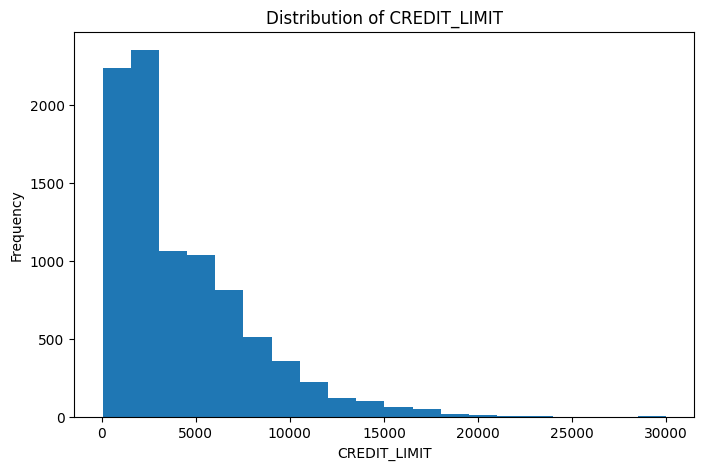

In [7]:
plt.figure(figsize=(8,5))
plt.hist(df['CREDIT_LIMIT'].dropna(), bins=20)
plt.xlabel('CREDIT_LIMIT')
plt.ylabel('Frequency')
plt.title('Distribution of CREDIT_LIMIT')
plt.show()

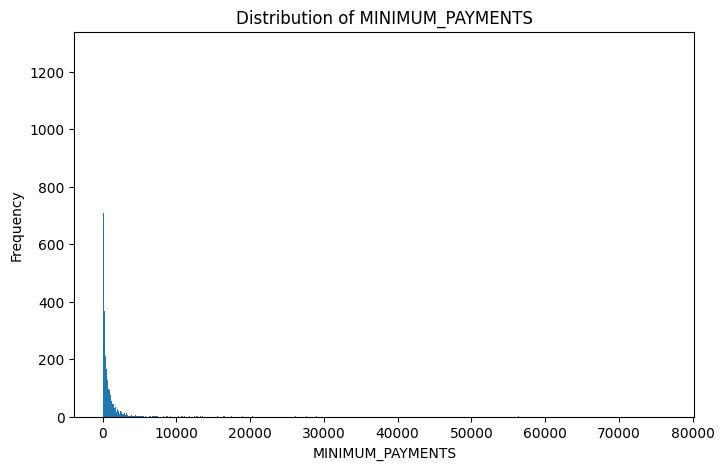

In [21]:
plt.figure(figsize=(8,5))
plt.hist(df['MINIMUM_PAYMENTS'].dropna(), bins=2000)
plt.xlabel('MINIMUM_PAYMENTS')
plt.ylabel('Frequency')
plt.title('Distribution of MINIMUM_PAYMENTS')
plt.show()

In [23]:
df['CREDIT_LIMIT'] = df['CREDIT_LIMIT'].fillna(df['CREDIT_LIMIT'].median())

In [22]:
df['MINIMUM_PAYMENTS'] = df['MINIMUM_PAYMENTS'].fillna(df['MINIMUM_PAYMENTS'].median())

In [24]:
print(df.isna().sum())

CUST_ID                             0
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
Cluster                             0
dtype: int64


In [25]:
X = df.drop(columns=["CUST_ID"]).copy()

In [13]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [14]:
rows = []
models = {}
for k in range(2, 11):
    model = KMeans(n_clusters=k, init="random", random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    rows.append({"K": k, "Inertia": model.inertia_,
                 "Silhouette Score": silhouette_score(X_scaled, labels)})
    models[k] = (model, labels)
scores = pd.DataFrame(rows)
display(scores.round(4))

,K,Inertia,Silhouette Score
0,2,127784.7006,0.2095
1,3,111973.6611,0.2506
2,4,99061.6775,0.1977
3,5,91490.3319,0.1932
4,6,84825.9703,0.2029
5,7,79505.9327,0.2152
6,8,75192.5868,0.2131
7,9,71070.9887,0.2155
8,10,66469.4939,0.2219


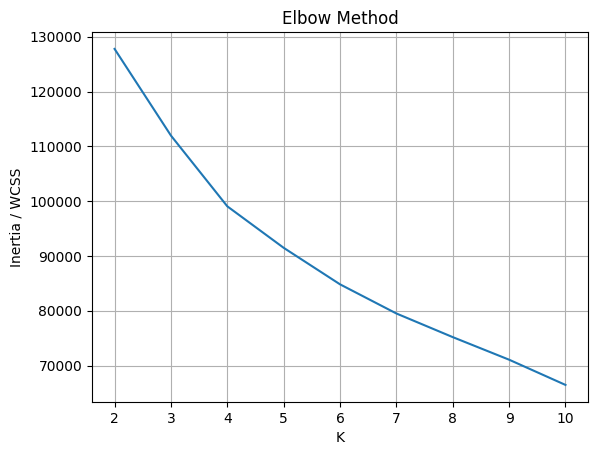

In [15]:
plt.plot(scores["K"], scores["Inertia"])
plt.xlabel("K")
plt.ylabel("Inertia / WCSS")
plt.title("Elbow Method")
plt.grid()
plt.show()



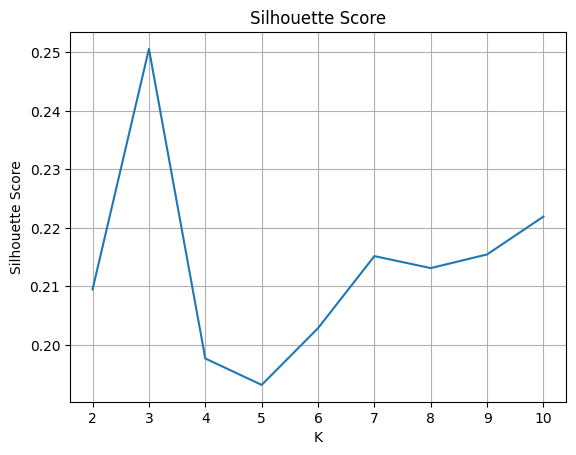

In [16]:
plt.plot(scores["K"], scores["Silhouette Score"])
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")
plt.grid()
plt.show()

In [17]:
# By visualizing the graphs the best k value is 3
best_k = 3
model, labels = models[best_k]

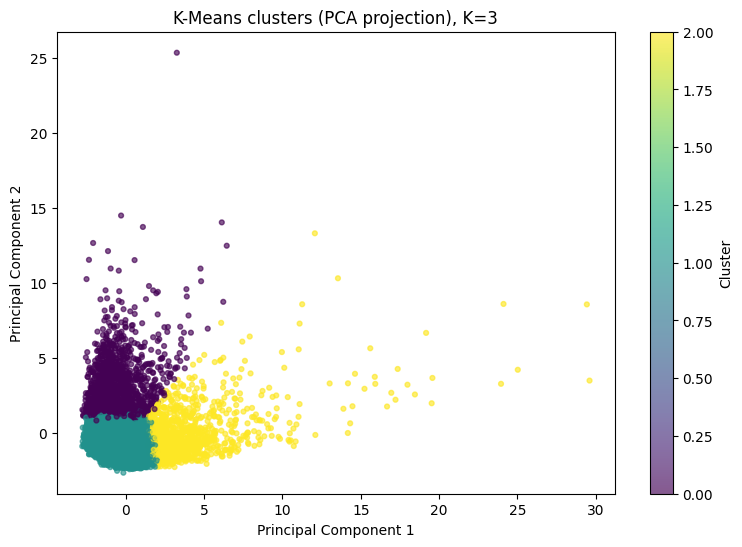

In [18]:
X_pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
plt.figure(figsize=(9, 6))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, s=12, alpha=0.65)
plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
plt.title(f"K-Means clusters (PCA projection), K={best_k}")
plt.colorbar(sc, label="Cluster"); plt.show()


In [19]:
df["Cluster"] = labels
display(df["Cluster"].value_counts().sort_index().to_frame("customers"))
df.to_csv("CC_GENERAL_kmeans_clusters.csv", index=False)

,customers
Cluster,
0,1596
1,6119
2,1235
